<!-- gs-watermark -->
> **© 2026 Gokaran Shukla** · part of [qslab](https://github.com/Gokaran-Shukla/qslab) · MIT License — any reuse must keep this copyright notice and credit the author.

# 02 · The Kitaev honeycomb model: an exactly solvable quantum spin liquid

$$H = -\sum_{\langle ij\rangle_\gamma} K_\gamma\,\sigma_i^\gamma\sigma_j^\gamma \qquad (\gamma=x,y,z)$$

**What you will learn**
1. Solve the model by brute-force ED and recognise the conserved fluxes $W_p$.
2. Solve it exactly with Majorana fermions, including the projection onto physical states, and check the result against ED.
3. Compute the thermodynamic-limit energy, Majorana cones, the phase diagram, the vison gap and correlations.
4. Add a magnetic field ($\kappa$ term) and obtain a chiral phase with Chern number ±1 (Ising anyons).
5. Simulate finite temperature with Majorana Monte Carlo and observe the two specific-heat peaks and the ½ ln2 plateau.

In [1]:
import numpy as np, matplotlib.pyplot as plt, time, itertools
import qslab
from qslab import lattice, models, ED
from qslab.kitaev import (KitaevMajorana, kitaev_energy_tl, kitaev_bloch, chern_number_fhs,
                          kitaev_phase, majorana_monte_carlo)

## 1. The lattice and the bond labels
qslab labels every nearest-neighbour honeycomb bond by its Kitaev type: x is red, y is green and z is blue.

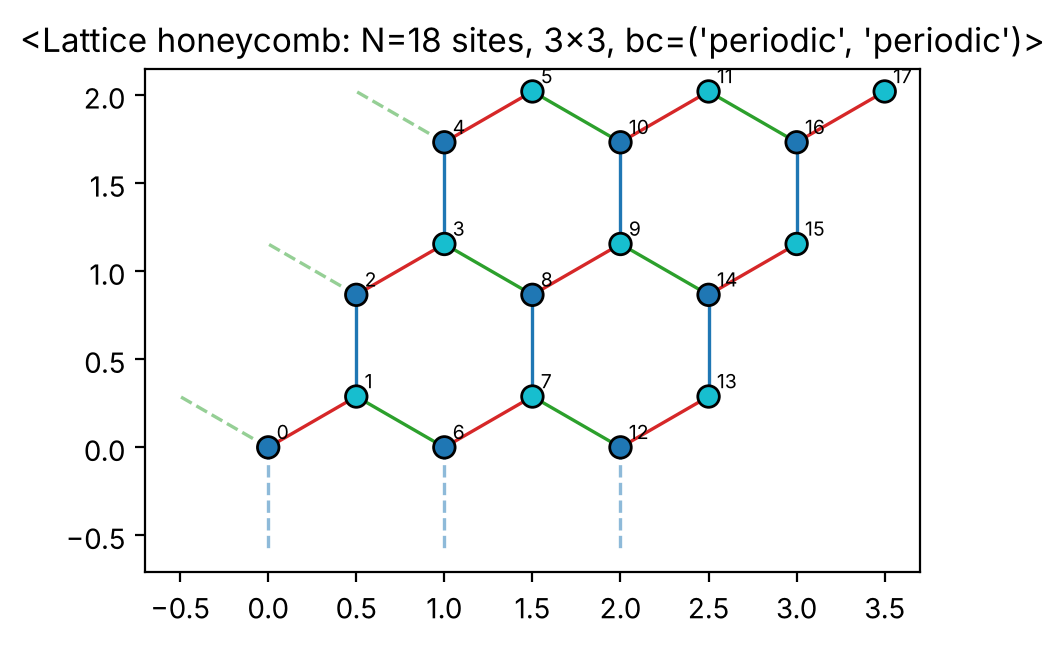

{'x': 9, 'y': 9, 'z': 9}


In [2]:
lat = lattice.honeycomb(3, 3)
lat.plot(); plt.show()
print({k: sum(b.kind == k for b in lat.bonds(1)) for k in "xyz"})

## 2. ED and conserved fluxes
$W_p=\sigma^x_1\sigma^y_2\sigma^z_3\sigma^x_4\sigma^y_5\sigma^z_6$ uses, on each vertex, the label of the bond that points **out** of the hexagon.
It commutes with $H$, and in the ground state $W_p = +1$ (Lieb's theorem).

In [3]:
H = models.kitaev(lat)
Wp = models.kitaev_plaquette_operators(lat)
print("all [H, W_p] = 0:", all(H.commutes_with(W) for W in Wp))
t = time.time(); ed = ED(H, lat.N); w, v = ed.diagonalize(k=4); print(ed, f"{time.time()-t:.1f}s")
print("lowest energies / N:", w / lat.N)
print("<W_p> in the ground state:", np.round([ed.expect(W, v[:, 0]) for W in Wp], 6))

all [H, W_p] = 0: True


<ED N=18 <SpinBasis N=18 full dim=262144> method=sparse> 5.5s
lowest energies / N: [-0.79397237 -0.79397237 -0.78192435 -0.77894533]
<W_p> in the ground state: [1. 1. 1. 1. 1. 1. 1. 1. 1.]


Spin correlations are **strictly nearest-neighbour**, which is the textbook signature of a spin liquid:

In [4]:
psi = v[:, 0]
i = 0
for j in range(lat.N):
    c = ed.expect(qslab.sigma(i, "z") * qslab.sigma(j, "z"), psi)
    if abs(c) > 1e-10 and j != i:
        print(f"<sz_{i} sz_{j}> = {c:+.6f}")

<sz_0 sz_5> = +0.534898


## 3. Exact Majorana solution
With $\sigma^a_j = i b^a_j c_j$ and the static gauge field $u_{jk} = i b_j b_k$, the Hamiltonian becomes $H_u = \frac{i}{4}\sum A_{jk}c_jc_k$ with $A_{jk} = 2K u_{jk}$.
A state is physical only if $\prod_j D_j = 1$. qslab computes this parity **numerically**, from the Pfaffian parity of the matter vacuum and the sign of the Majorana permutation, so there is no lattice-specific formula to get wrong.

**Check 1:** on 8 sites, enumerate *every* gauge configuration and fermion occupation. The resulting physical spectrum reproduces the full ED spectrum, with uniform multiplicity equal to the gauge redundancy.

In [5]:
lat8 = lattice.honeycomb(2, 2)
km8 = KitaevMajorana(lat8)
levels = {}
for bits in itertools.product([1, -1], repeat=km8.nb):
    u = np.array(bits, float)
    eps = km8.spectrum(u); E0 = -0.5 * eps.sum(); P = km8.is_physical(u)
    for occ in itertools.product([0, 1], repeat=len(eps)):
        if (sum(occ) % 2 == 0) == P:
            e = round(E0 + np.dot(occ, eps), 7); levels[e] = levels.get(e, 0) + 1
w_ed = np.linalg.eigvalsh(models.kitaev(lat8).to_matrix(8))
ed_levels = {}
for e in w_ed:
    ed_levels[round(e, 7)] = ed_levels.get(round(e, 7), 0) + 1
print("same set of levels:", set(levels) == set(ed_levels),
      "| multiplicity ratio:", {levels[k] // ed_levels[k] for k in ed_levels})

same set of levels: True | multiplicity ratio: {128}


**Check 2:** on 18 sites the Majorana solution and ED agree to about $10^{-8}$.

In [6]:
km = KitaevMajorana(lat)
print("Majorana:", km.ground_state_energy(), "  ED:", w[0])
for sec, d in km.sector_energies().items():
    print(f"  Wilson sector {sec}: vacuum physical={d['vacuum_is_physical']}, E_phys={d['E_physical']:.6f}")

Majorana: -14.291502622129183   ED: -14.291502622129205
  Wilson sector (1, 1): vacuum physical=True, E_phys=-13.392305
  Wilson sector (1, -1): vacuum physical=True, E_phys=-14.291503
  Wilson sector (-1, 1): vacuum physical=True, E_phys=-14.291503
  Wilson sector (-1, -1): vacuum physical=True, E_phys=-14.291503


## 4. Thermodynamic limit, Majorana cones and the phase diagram

In [7]:
print("E/N (TL, BZ integral):", kitaev_energy_tl(nk=200))
for L in [6, 12, 24]:
    print(f"  L={L:2d} torus: {KitaevMajorana(lattice.honeycomb(L, L)).ground_state_energy()/(2*L*L):.6f}")

E/N (TL, BZ integral): -0.7872986133129583
  L= 6 torus: -0.788236


  L=12 torus: -0.787422


  L=24 torus: -0.787314


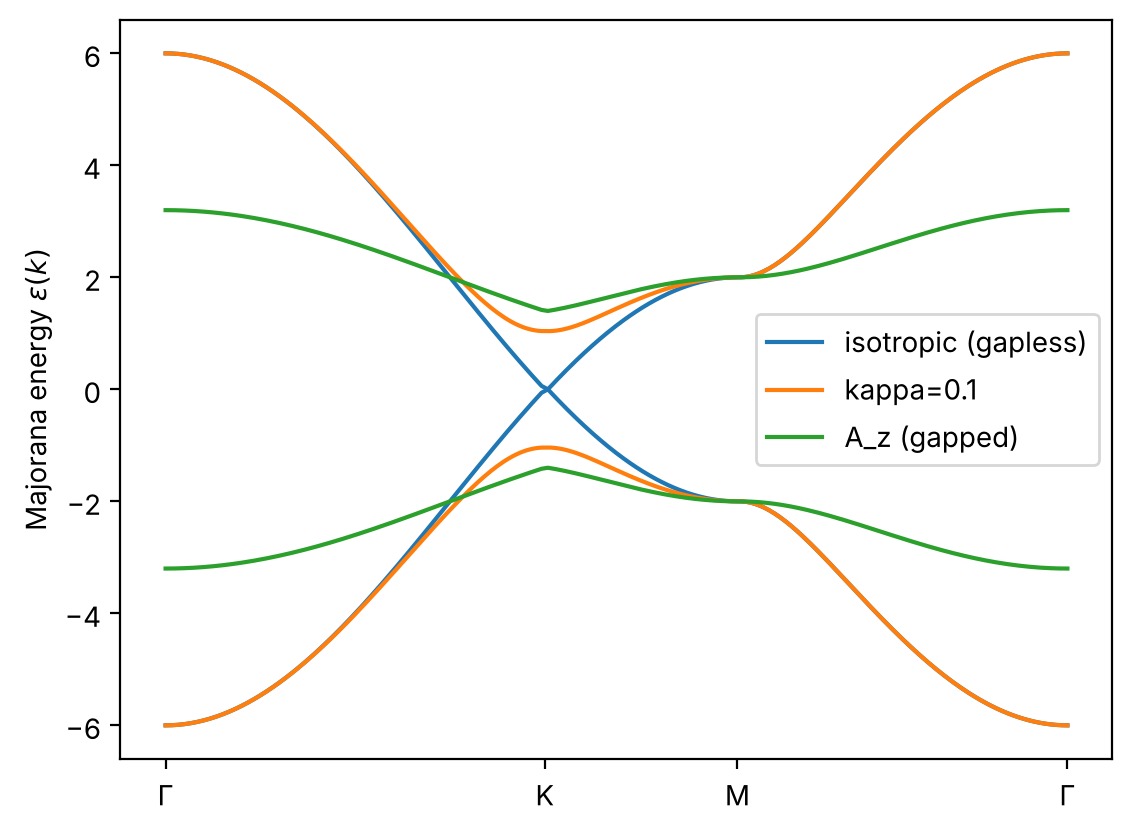

In [8]:
lat1 = lattice.honeycomb(1, 1)
ks, dist, ticks = lat1.kpath(["G", "K", "M", "G"], n=120)
for K, lab in [((1, 1, 1), "isotropic (gapless)"), ((1, 1, 1), "kappa=0.1"), ((0.3, 0.3, 1), "A_z (gapped)")]:
    kap = 0.1 if "kappa" in lab else 0
    e = [np.linalg.eigvalsh(kitaev_bloch(k, K, kap))[1] for k in ks]
    plt.plot(dist, e, label=lab); plt.plot(dist, -np.array(e), color=plt.gca().lines[-1].get_color())
plt.xticks(ticks, ["Γ", "K", "M", "Γ"]); plt.ylabel(r"Majorana energy $\varepsilon(k)$"); plt.legend(); plt.show()

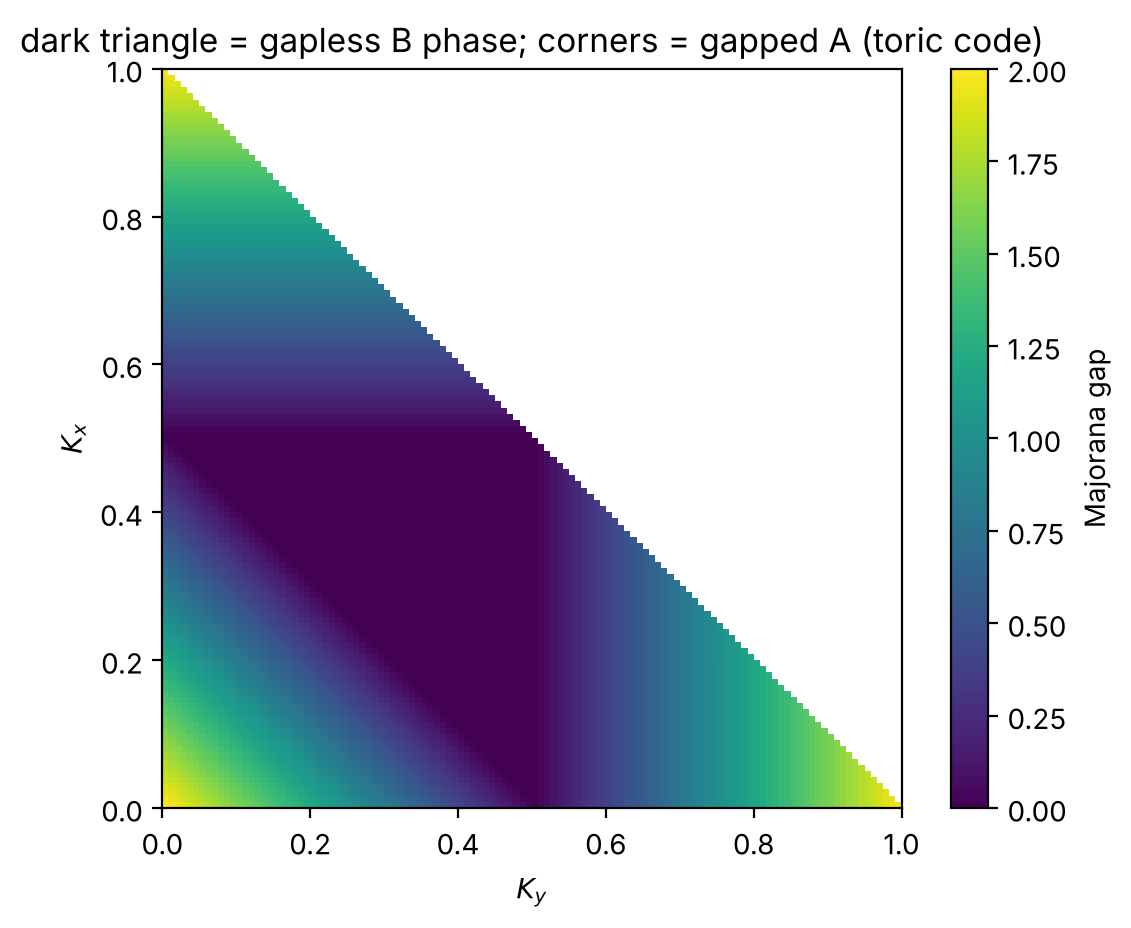

In [9]:
# phase diagram on the Kx + Ky + Kz = 1 triangle: the minimal Majorana gap
n = 120; img = np.full((n, n), np.nan)
B = lat1.reciprocal(); grid = [(a/24)*B[0] + (b/24)*B[1] for a in range(24) for b in range(24)]
for a in range(n):
    for b in range(n - a):
        Kx, Ky = a / n, b / n; Kz = 1 - Kx - Ky
        img[a, b] = 0.0 if kitaev_phase((Kx, Ky, Kz)).startswith("B") else \
            min(np.linalg.eigvalsh(kitaev_bloch(k, (Kx, Ky, Kz)))[1] for k in grid)
plt.imshow(img, origin="lower", extent=[0, 1, 0, 1]); plt.colorbar(label="Majorana gap")
plt.xlabel("$K_y$"); plt.ylabel("$K_x$"); plt.title("dark triangle = gapless B phase; corners = gapped A (toric code)"); plt.show()

## 5. Visons, correlations and the chiral phase

In [10]:
kmL = KitaevMajorana(lattice.honeycomb(20, 20))
print("vison-pair energy:", kmL.vison_pair_energy())
print("NN correlations <σσ>:", kmL.bond_correlations())
B = lat1.reciprocal()
for kap in [0.05, -0.05]:
    print(f"kappa={kap:+}: Chern number of lower Majorana band =",
          round(chern_number_fhs(lambda k: kitaev_bloch(k, (1, 1, 1), kap), B, nk=36), 6))

vison-pair energy: 0.2650193423401106


NN correlations <σσ>: {'x': 0.5248833079910193, 'y': 0.5248833079910192, 'z': 0.5248833079910192}
kappa=+0.05: Chern number of lower Majorana band = -1.0
kappa=-0.05: Chern number of lower Majorana band = 1.0


The κ-term is a genuine 3-spin operator. ED with that term reproduces the Majorana result
(8 sites, minimum over all 4096 gauge configurations):

In [11]:
E_ed = ED(models.kitaev(lat8, kappa=0.1), 8).ground_state()[0]
km8k = KitaevMajorana(lat8, kappa=0.1)
E_maj = min(km8k.physical_energy(np.array(b, float)) for b in itertools.product([1, -1], repeat=km8k.nb))
print("ED:", E_ed, "  Majorana (all gauges):", E_maj)

ED: -6.928203230275499   Majorana (all gauges): -6.928203230275509


## 6. Finite temperature: Majorana Monte Carlo
Monte Carlo sampling of the gauge field is free of the sign problem. Each temperature is an independent Markov chain, run in parallel with `pmap` on processes or MPI ranks.
**Physics:** there are two specific-heat peaks. Itinerant Majoranas freeze out at $T_H\approx1.5K$, and the $Z_2$ fluxes order at $T_L\approx0.05K$ in the thermodynamic limit. Small clusters push $T_L$ up.
In between, the entropy has a $\tfrac12\ln 2$ plateau. In the spin-operator units of Nasu *et al.* ($J=4K$) these temperatures are $0.375J$ and $0.012J$.

38s


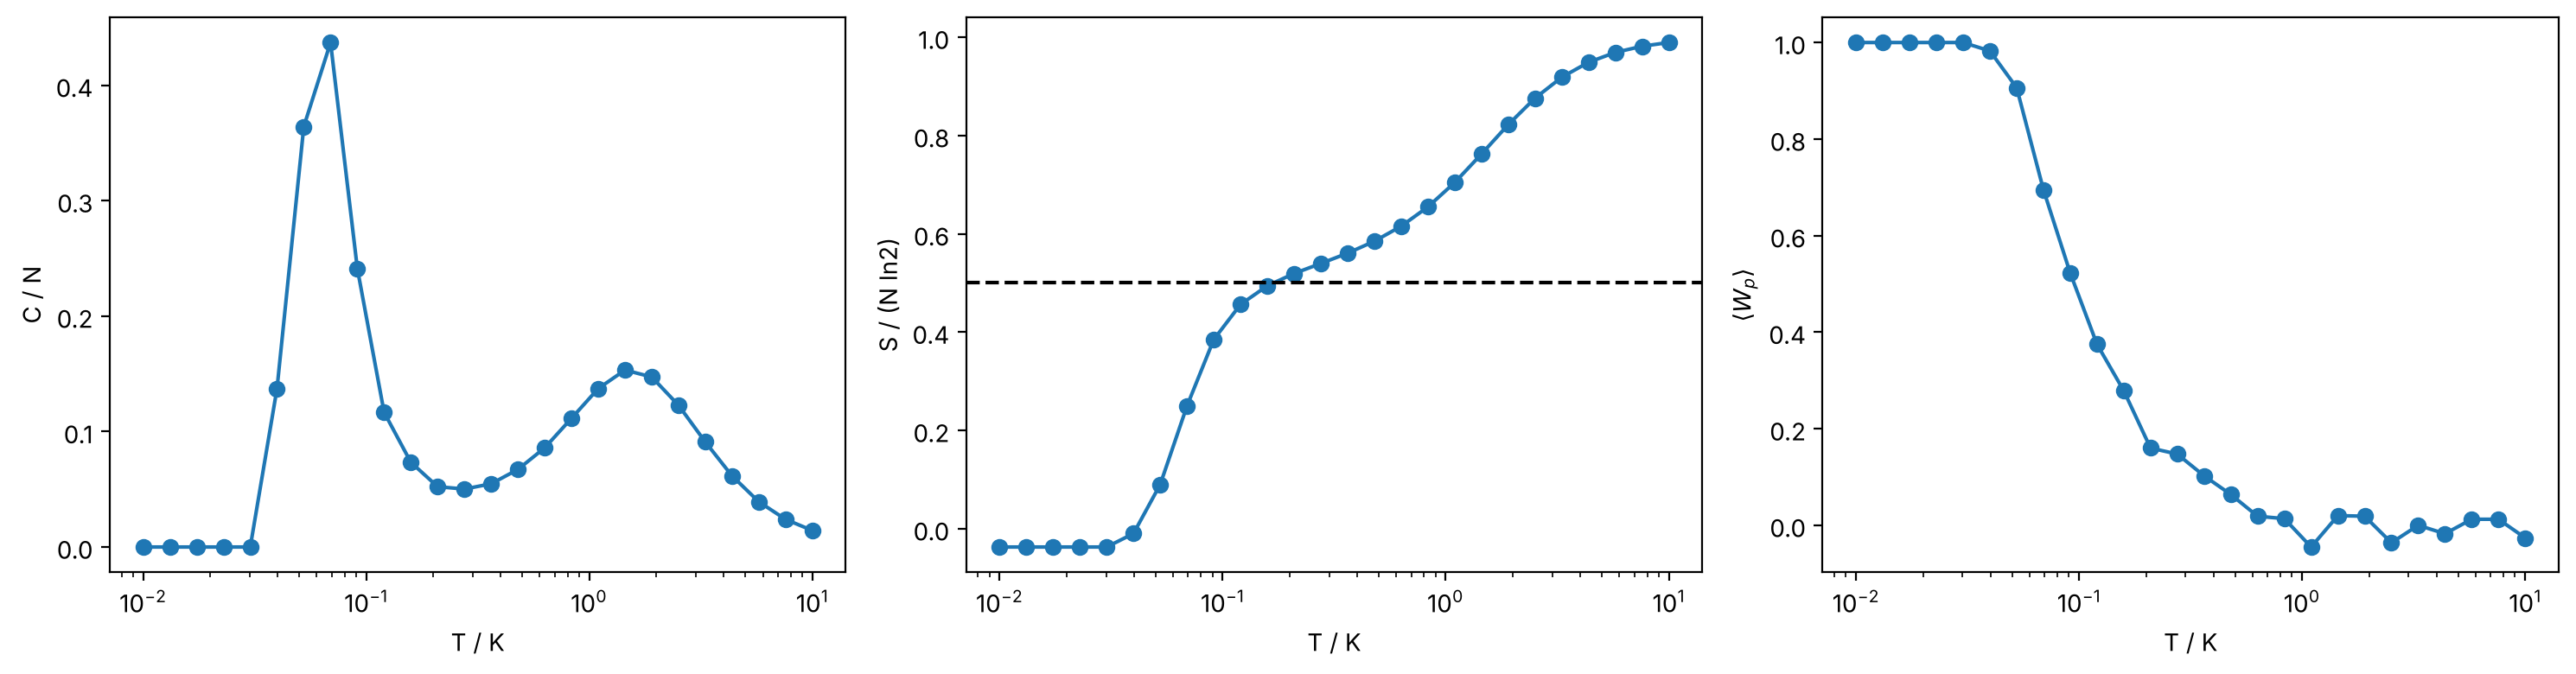

In [12]:
Ts = np.geomspace(0.01, 10, 26)
t = time.time()
mc = majorana_monte_carlo(L=4, temperatures=Ts, n_therm=100, n_meas=200)
print(f"{time.time()-t:.0f}s")
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].semilogx(mc["T"], mc["C"], "o-"); ax[0].set_ylabel("C / N")
ax[1].semilogx(mc["T"], mc["S"] / np.log(2), "o-"); ax[1].axhline(0.5, ls="--", c="k"); ax[1].set_ylabel("S / (N ln2)")
ax[2].semilogx(mc["T"], mc["W"], "o-"); ax[2].set_ylabel(r"$\langle W_p\rangle$")
for a in ax: a.set_xlabel("T / K")
plt.tight_layout(); plt.show()

## Exercises
1. Move along $K_x=K_y$ toward $K_z\to1$ and check that the Majorana gap opens at $K_z = K_x + K_y$.
2. Compute the vison-pair energy versus system size; why does it converge quickly?
3. Measure $\langle W_p\rangle$ in ED with a small [111] field and see how it decreases.

## Quiz

In [13]:
from qslab import quiz
quiz.show("kitaev")

=== Kitaev honeycomb model ===
H = -sum K_g sigma^g sigma^g on x, y, z bonds (Pauli units unless stated).

Q1. [mcq] Which operators commute with the Kitaev Hamiltonian on every hexagon?
    (a) sum_i sigma^z_i
    (b) S_i . S_j on z bonds
    (c) W_p = sigma^x sigma^y sigma^z sigma^x sigma^y sigma^z (outward bond labels)
    (d) S_tot^z

Q2. [mcq] In Kitaev's representation sigma^a_j = i b^a_j c_j, what physical constraint must states satisfy?
    (a) b^x b^y b^z c = 1 on every site (D_j = 1)
    (b) fermion number = N/2
    (c) u_jk = +1 on all bonds
    (d) sum_j c_j = 0

Q3. [mcq] Lieb's theorem implies the ground state of the Kitaev model lies in which flux sector (for large clusters)?
    (a) W_p = -1 on all plaquettes
    (b) W_p = +1 on all plaquettes (flux-free)
    (c) alternating fluxes
    (d) random fluxes

Q4. [numeric] Ground-state energy per site of the isotropic Kitaev model (K = 1, Pauli units) in the thermodynamic limit?
    -> numeric answer (tolerance 0.0002)
    h